# Lab – Sequence Models for NLP (PyTorch) · **Part 2: Text generation with GPT-2 (Transformer)**

**My Goal:** In this part of the lab, I loaded the pre-trained **GPT-2** model, **fine-tuned** it on a customized dataset about Artificial Intelligence that I scraped from Wikipedia, and then **generated new paragraphs starting from specific prompt sentences** to see how well it adapted.

### Overview of my workflow:
1. Installed the required `transformers` library, loaded the pre-trained GPT-2 model, and set up its BPE tokenizer.
2. Built a **customized corpus** of paragraphs about AI and Machine Learning from Wikipedia (similar to the topic in Part 1).
3. Tokenized the text, split the data by article, and evaluated the **perplexity of the original pre-trained model** on our domain as a baseline.
4. **Fine-tuned** GPT-2 using AdamW, linear learning rate warmup/decay, mixed precision, and gradient accumulation, saving the best-performing checkpoint.
5. Compared perplexity **before and after** fine-tuning to measure improvement.
6. **Generated new paragraphs** starting from specific prompts to contrast the pre-trained vs. fine-tuned outputs, and compared different decoding strategies (greedy, beam search, temperature, top-k, and top-p).
7. Conducted a quantitative evaluation of the generated texts using metrics like BLEU, lexical diversity (distinct-n), and the rate at which the model naturally terminates paragraphs.

> **A note on the library:** The original guidelines suggested `pytorch-transformers`. Since that library was renamed to Hugging Face's **`transformers`**, I used the updated and maintained version. It exposes the same `GPT2LMHeadModel` and `GPT2Tokenizer` classes.

In [1]:
# torch, pandas, matplotlib, scikit-learn are already installed on Colab / Kaggle
!pip install -q transformers nltk tqdm

In [2]:
import os, re, math, time, random, shutil, textwrap, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import transformers
from transformers import GPT2LMHeadModel, GPT2Tokenizer, get_linear_schedule_with_warmup
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# ------------------------------ configuration ------------------------------
FAST_DEBUG   = False        # True -> tiny run (few paragraphs, 2 short epochs) just to check that everything executes
REFRESH_DATA = False        # True -> scrape Wikipedia again even if data/gpt2_dataset.csv exists
SEED         = 42
MODEL_NAME   = "gpt2"       # "gpt2" (124M parameters). "gpt2-medium" (355M) is better but needs a smaller BATCH_SIZE

DATA_DIR, MODEL_DIR = "data", "models"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(MODEL_DIR, exist_ok=True)
CORPUS_CSV = f"{DATA_DIR}/gpt2_dataset{'_debug' if FAST_DEBUG else ''}.csv"   # the customised dataset (title, text); separate file in debug mode
CUSTOM_TXT = f"{DATA_DIR}/custom_corpus.txt"         # OPTIONAL: your own paragraphs, one per line (added to the dataset)
OUT_DIR    = f"{MODEL_DIR}/gpt2-finetuned"           # where the best fine-tuned checkpoint is saved

# ---- data ----
MAX_PARAGRAPHS = 2500       # cap on the number of paragraphs (keeps training short)
MIN_WORDS, MAX_WORDS = 40, 140                       # size of one training paragraph
MAX_LEN = 256               # max tokens per training sequence (paragraph + <|endoftext|>)
# ---- training ----
BATCH_SIZE, GRAD_ACCUM = 8, 2          # effective batch size = 16 paragraphs
EPOCHS        = 3
LR            = 5e-5
WARMUP_RATIO  = 0.06
WEIGHT_DECAY  = 0.01
GRAD_CLIP     = 1.0
# ---- evaluation ----
N_EVAL_PROMPTS = 60

if FAST_DEBUG:
    MAX_PARAGRAPHS, EPOCHS, N_EVAL_PROMPTS = 240, 2, 8

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {DEVICE} | torch {torch.__version__} | transformers {transformers.__version__}")
if DEVICE.type == "cpu" and not FAST_DEBUG:
    print("WARNING: no GPU detected. Enable one (Runtime > Change runtime type > T4 GPU) or set FAST_DEBUG = True.")

device: cuda | torch 2.14.1+cu130 | transformers 5.22.1


## 1 · Loading the pre-trained GPT-2

GPT-2 is a **decoder-only Transformer** trained to predict the next token given the previous context (causal language modeling). It uses **byte-level BPE** tokenization with a vocabulary of 50,257 tokens, and uses `<|endoftext|>` to mark document boundaries.

I loaded the model **twice**:
* `base_model`: Left untouched as our original "before" baseline.
* `model`: The instance that I actually fine-tuned on the new corpus.

Since GPT-2 doesn't have a default padding token, I configured `<|endoftext|>` to double as the padding token. I ensured that padding positions are masked out during loss calculation, while keeping the actual end-of-text tokens so the model can learn where a paragraph naturally ends.

In [3]:
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token                       # <|endoftext|> doubles as padding token

base_model = GPT2LMHeadModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()   # reference: pre-trained, never trained by us
model      = GPT2LMHeadModel.from_pretrained(MODEL_NAME).to(DEVICE)          # the one we fine-tune
for m in (base_model, model): m.config.pad_token_id = tokenizer.eos_token_id

cfg = model.config
n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME}: {n_params/1e6:.0f}M parameters | {cfg.n_layer} layers, {cfg.n_head} heads, hidden size {cfg.n_embd}, "
      f"context {cfg.n_positions} tokens, vocabulary {cfg.vocab_size}")

# ---- what does the tokenizer do? ----
example = "Recurrent neural networks process sequences."
ids = tokenizer.encode(example)
print("\ntext   :", example)
print("tokens :", tokenizer.convert_ids_to_tokens(ids), " (Ġ = a leading space)")
print("ids    :", ids)
print("eos    :", tokenizer.eos_token, tokenizer.eos_token_id)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

gpt2: 124M parameters | 12 layers, 12 heads, hidden size 768, context 1024 tokens, vocabulary 50257

text   : Recurrent neural networks process sequences.
tokens : ['Rec', 'urrent', 'Ġneural', 'Ġnetworks', 'Ġprocess', 'Ġsequences', '.']  (Ġ = a leading space)
ids    : [6690, 6657, 17019, 7686, 1429, 16311, 13]
eos    : <|endoftext|> 50256


In [4]:
def show(title, text, width=110):
    print(f"--- {title}"); print(textwrap.fill(text.replace("\n", " "), width=width)); print()

def generate(m, prompts, max_new_tokens=120, min_new_tokens=0, do_sample=True, temperature=0.8, top_k=50, top_p=0.92,
             repetition_penalty=1.1, no_repeat_ngram_size=0, num_beams=1, num_return_sequences=1, seed=None, return_meta=False):
    # Generates a continuation for each prompt. Returns the continuations only (the prompt is NOT repeated).
    # With return_meta=True it also returns, for each output, whether the model produced <|endoftext|> by itself.
    if isinstance(prompts, str): prompts = [prompts]
    if seed is not None: set_seed(seed)
    m.eval()
    tokenizer.padding_side = "left"                       # decoder-only models must be padded on the left for generation
    enc = tokenizer(prompts, return_tensors="pt", padding=True).to(DEVICE)
    kw = dict(max_new_tokens=max_new_tokens, min_new_tokens=min_new_tokens, repetition_penalty=repetition_penalty,
              no_repeat_ngram_size=no_repeat_ngram_size, num_beams=num_beams, num_return_sequences=num_return_sequences,
              pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id)
    if do_sample: kw.update(do_sample=True, temperature=temperature, top_k=top_k, top_p=top_p)
    else:         kw.update(do_sample=False)
    if num_beams > 1: kw["early_stopping"] = True
    with torch.no_grad():
        out = m.generate(**enc, **kw)
    new = out[:, enc["input_ids"].shape[1]:]
    texts = [tokenizer.decode(row.tolist(), skip_special_tokens=True) for row in new]
    if return_meta:
        return texts, (new == tokenizer.eos_token_id).any(dim=1).tolist()
    return texts

# quick check of the pre-trained model (it has never seen our dataset)
p = "Artificial intelligence is the ability of machines to perform tasks that normally require human intelligence."
show("pre-trained GPT-2, before any fine-tuning", p + generate(base_model, p, seed=SEED, min_new_tokens=40)[0])

--- pre-trained GPT-2, before any fine-tuning
Artificial intelligence is the ability of machines to perform tasks that normally require human intelligence.
It has been shown in some experiments, such as neural networks (the algorithms developed by IBM), or deep
learning programs like Deep Learning and Machine Intelligence which are designed to be able "to do things we
can't even imagine". The technology's potential for new applications comes from its vast breadth and depth of
experience – not just a few examples but also many thousands of others too: it could make cars smarter than
humans at working speeds; automate medical procedures faster because doctors have more time on their hands
rather then using an expensive machine-learning platform when they need them most."



## 2 · Building our customized dataset

To make a specialized corpus, I gathered paragraphs about **Artificial Intelligence and Machine Learning** from approximately 50 English Wikipedia articles using the **MediaWiki API** (which gives clean plain text instead of messy HTML).

### My data cleaning pipeline:
1. Stripped out irrelevant footer sections (like *See also, References, External links*, etc.).
2. Filtered for real paragraphs (at least 150 characters long, ending with proper punctuation, mostly ASCII characters, and skipping mathematical expressions).
3. Standardized paragraph lengths by splitting long texts at sentence boundaries (keeping pieces between 40 and 140 words).
4. Dropped duplicates and capped the corpus size using `MAX_PARAGRAPHS` to keep training times reasonable.

**Why this is a great test for fine-tuning:** The GPT-2 model originally had Wikipedia content omitted from its WebText training data. This technical, encyclopedic style is distinct from standard web crawls, so evaluating the perplexity on held-out test articles is a perfect test of how well the model adapts.

In [5]:
WIKI_API = "https://en.wikipedia.org/w/api.php"
HEADERS  = {"User-Agent": "MBD-DeepLearning-Lab/1.0 (student project; replace with your e-mail)"}   # Wikipedia asks for an identifiable UA

WIKI_TITLES = [
    "Artificial intelligence", "Machine learning", "Deep learning", "Artificial neural network", "Recurrent neural network",
    "Long short-term memory", "Gated recurrent unit", "Convolutional neural network", "Transformer (deep learning architecture)",
    "Attention (machine learning)", "Generative pre-trained transformer", "GPT-2", "Large language model",
    "Natural language processing", "Natural language generation", "Word embedding", "Language model", "Machine translation",
    "Speech recognition", "Sentiment analysis", "Computer vision", "Reinforcement learning", "Supervised learning",
    "Unsupervised learning", "Transfer learning", "Backpropagation", "Gradient descent", "Overfitting", "Autoencoder",
    "Generative adversarial network", "Support vector machine", "Decision tree learning", "Random forest",
    "K-means clustering", "Data mining", "Data science", "Big data", "Chatbot", "Recommender system", "Robotics",
    "Expert system", "Turing test", "History of artificial intelligence", "Ethics of artificial intelligence",
    "Intelligent agent", "Self-driving car", "Knowledge representation and reasoning", "Perplexity", "BLEU",
    "Fine-tuning (deep learning)",
]
SKIP_SECTIONS = {"see also", "references", "external links", "further reading", "notes", "bibliography", "sources", "citations"}
ENDINGS = (".", "!", "?", '"', "”", ")")
SENT_SPLIT = re.compile(r'(?<=[.!?])\s+(?=[A-Z0-9"“(])')

def fetch_wiki_text(title, retries=2):
    # plain-text extract of a whole article ("" if it fails)
    params = dict(action="query", prop="extracts", explaintext=1, exsectionformat="wiki", titles=title,
                  format="json", redirects=1)
    for attempt in range(retries + 1):
        try:
            r = requests.get(WIKI_API, params=params, headers=HEADERS, timeout=30)
            if r.status_code == 200:
                page = next(iter(r.json()["query"]["pages"].values()))
                return page.get("extract", "")
        except Exception:
            pass
        time.sleep(1.5 * (attempt + 1))
    return ""

def clean_article(text):
    # returns the list of clean paragraphs of an article
    out, skip = [], False
    for line in text.replace("\xa0", " ").replace("​", "").split("\n"):
        line = line.strip()
        if not line: continue
        m = re.match(r"^=+\s*(.*?)\s*=+$", line)                       # "== History ==" -> section heading
        if m:
            skip = m.group(1).strip().lower() in SKIP_SECTIONS
            continue
        if skip: continue
        line = re.sub(r"\[(\d+|citation needed|[a-z])\]", "", line)
        line = re.sub(r"\s+", " ", line).strip()
        if "displaystyle" in line or "\\" in line: continue            # maths markup
        if len(line) < 150 or not line.endswith(ENDINGS): continue     # headings, list items, captions
        if sum(c.isascii() for c in line) / len(line) < 0.93: continue # not English
        out.append(line)
    return out

def split_sentences(text):
    return [s.strip() for s in SENT_SPLIT.split(text) if s.strip()]

def paragraph_chunks(par, min_words=MIN_WORDS, max_words=MAX_WORDS):
    # cuts a long paragraph into pieces of <= max_words words, always at sentence boundaries
    chunks, cur, n = [], [], 0
    for s in split_sentences(par):
        w = len(s.split())
        if cur and n + w > max_words:
            chunks.append(" ".join(cur)); cur, n = [], 0
        cur.append(s); n += w
    if cur: chunks.append(" ".join(cur))
    return [c for c in chunks if len(c.split()) >= min_words]

def build_dataset():
    rows, failed = [], []
    for title in tqdm(WIKI_TITLES, desc="Wikipedia"):
        text = fetch_wiki_text(title)
        chunks = [c for p in clean_article(text) for c in paragraph_chunks(p)] if text else []
        if chunks: rows += [dict(title=title, text=c) for c in chunks]
        else:      failed.append(title)
        time.sleep(0.3)                                                # be polite with the API
    return pd.DataFrame(rows, columns=["title", "text"]), failed

In [6]:
MIN_REQUIRED = 150

if os.path.exists(CORPUS_CSV) and not REFRESH_DATA:
    df = pd.read_csv(CORPUS_CSV, encoding="utf-8")
    print(f"loaded cached {CORPUS_CSV}")
else:
    df, failed = build_dataset()
    if failed: print(f"{len(failed)} articles gave nothing: {failed}")
    if os.path.exists(CUSTOM_TXT):                                     # optional user-provided paragraphs
        with open(CUSTOM_TXT, encoding="utf-8") as f:
            mine = [l.strip() for l in f if len(l.split()) >= MIN_WORDS]
        df = pd.concat([df, pd.DataFrame(dict(title="custom", text=mine))], ignore_index=True)
        print(f"added {len(mine)} paragraphs from {CUSTOM_TXT}")
    df = df.drop_duplicates("text").reset_index(drop=True)
    if len(df) > MAX_PARAGRAPHS:
        df = df.sample(MAX_PARAGRAPHS, random_state=SEED).sort_index().reset_index(drop=True)
    if len(df) < MIN_REQUIRED:
        raise RuntimeError(f"Only {len(df)} paragraphs collected (need >= {MIN_REQUIRED}). Check that the notebook has Internet "
                           f"access, or put your own paragraphs (one per line) in {CUSTOM_TXT} and run again.")
    df.to_csv(CORPUS_CSV, index=False, encoding="utf-8")
    print(f"saved {CORPUS_CSV}")

df = df.dropna().reset_index(drop=True)
words_per_par = df["text"].str.split().map(len)
print(f"\n{len(df)} paragraphs from {df['title'].nunique()} articles | {words_per_par.sum():,} words | "
      f"{words_per_par.mean():.0f} words per paragraph on average")
pd.set_option("display.max_colwidth", 140)
display(df.sample(3, random_state=SEED))

# ---------- split BY ARTICLE (80 / 10 / 10): paragraphs of one article never appear in two splits ----------
rng = random.Random(SEED)
titles = sorted(df["title"].unique()); rng.shuffle(titles)
if len(titles) >= 5:
    n_hold = max(1, round(0.1 * len(titles)))
    test_titles, val_titles = set(titles[:n_hold]), set(titles[n_hold:2 * n_hold])
    df["split"] = df["title"].map(lambda t: "test" if t in test_titles else "val" if t in val_titles else "train")
else:                                                                  # too few articles -> random split of the paragraphs
    df["split"] = rng.choices(["train", "val", "test"], weights=[8, 1, 1], k=len(df))
print("\nparagraphs per split:", df["split"].value_counts().to_dict())
if len(titles) >= 5: print("held-out test articles:", sorted(test_titles))

Wikipedia:   0%|          | 0/50 [00:00<?, ?it/s]

15 articles gave nothing: ['Generative pre-trained transformer', 'GPT-2', 'Large language model', 'Natural language processing', 'Natural language generation', 'Backpropagation', 'Gradient descent', 'Overfitting', 'Autoencoder', 'Generative adversarial network', 'Expert system', 'Turing test', 'History of artificial intelligence', 'Ethics of artificial intelligence', 'Intelligent agent']
saved data/gpt2_dataset.csv

1535 paragraphs from 35 articles | 117,997 words | 77 words per paragraph on average


,title,text
1159,Big data,Teradata Corporation in 1984 marketed the parallel processing DBC 1012 system. Teradata systems were the first to store and analyze 1 te...
76,Artificial intelligence,"Artificial intelligence provides a number of tools that are useful to bad actors, such as authoritarian governments, terrorists, crimina..."
316,Artificial neural network,Groups of neurons are aggregated into layers. Each layer performs a transformation on its inputs. Signals travel from the first layer (t...



paragraphs per split: {'train': 1364, 'val': 102, 'test': 69}
held-out test articles: ['Chatbot', 'Data science', 'Fine-tuning (deep learning)', 'Perplexity']


## 3 · Tokenization, Data Loaders, and Baseline Evaluation

I formatted every paragraph in the dataset to end with the `<|endoftext|>` token. To handle varying paragraph lengths efficiently, I implemented **dynamic right-padding** inside each batch and masked those padding values from the loss function.

I calculated **Perplexity** (defined as `exp(mean negative log-likelihood per token)`) on the held-out paragraphs. This gives us an intuitive metric: *on average, how many different tokens is the model choosing between?* Lower is better. I started by evaluating the untouched, pre-trained GPT-2 to establish our baseline.

In [7]:
df["ids"] = df["text"].map(lambda t: tokenizer.encode(t) + [tokenizer.eos_token_id])
n_before = len(df)
df = df[df["ids"].map(len) <= MAX_LEN].reset_index(drop=True)
lens = df["ids"].map(len)
print(f"{len(df)} sequences kept ({n_before - len(df)} dropped for being longer than {MAX_LEN} tokens) | "
      f"tokens per sequence: mean {lens.mean():.0f}, max {lens.max()} | total {lens.sum():,} tokens")

class ParagraphDataset(Dataset):
    def __init__(self, id_lists): self.data = list(id_lists)
    def __len__(self): return len(self.data)
    def __getitem__(self, i): return torch.tensor(self.data[i], dtype=torch.long)

def collate(batch):
    L = max(len(x) for x in batch)
    input_ids = torch.full((len(batch), L), tokenizer.eos_token_id, dtype=torch.long)
    attn = torch.zeros((len(batch), L), dtype=torch.long)
    for i, x in enumerate(batch):
        input_ids[i, :len(x)] = x; attn[i, :len(x)] = 1
    labels = input_ids.masked_fill(attn == 0, -100)       # mask the PADDING (by position), keep the real <|endoftext|> in the loss
    return input_ids, attn, labels

def make_loader(split, batch_size, shuffle):
    ds = ParagraphDataset(df.loc[df["split"] == split, "ids"])
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=collate, generator=g)

train_loader, val_loader, test_loader = make_loader("train", BATCH_SIZE, True), make_loader("val", 16, False), make_loader("test", 16, False)
print(f"batches: train {len(train_loader)} | val {len(val_loader)} | test {len(test_loader)}")

def lm_loss(logits, labels, reduction="mean"):
    # next-token cross-entropy: the logits at position t predict the token at position t+1
    return F.cross_entropy(logits[:, :-1].float().reshape(-1, logits.size(-1)), labels[:, 1:].reshape(-1),
                           ignore_index=-100, reduction=reduction)

@torch.no_grad()
def evaluate_ppl(m, loader):
    m.eval(); total_nll, total_tok = 0.0, 0
    for ids, attn, labels in loader:
        ids, attn, labels = ids.to(DEVICE), attn.to(DEVICE), labels.to(DEVICE)
        logits = m(input_ids=ids, attention_mask=attn).logits
        total_nll += lm_loss(logits, labels, reduction="sum").item()
        total_tok += (labels[:, 1:] != -100).sum().item()
    return math.exp(total_nll / total_tok)

ppl_before = {"val": evaluate_ppl(base_model, val_loader), "test": evaluate_ppl(base_model, test_loader)}
print(f"\npre-trained GPT-2 perplexity on our domain -> validation: {ppl_before['val']:.2f} | test: {ppl_before['test']:.2f}")

1533 sequences kept (2 dropped for being longer than 256 tokens) | tokens per sequence: mean 100, max 256 | total 153,370 tokens
batches: train 171 | val 7 | test 5

pre-trained GPT-2 perplexity on our domain -> validation: 40.86 | test: 38.66


## 4 · Fine-tuning the Model

For the fine-tuning process, I continued training the pre-trained weights on our specialized AI dataset using a small learning rate to avoid erasing the model's general knowledge.

### Training Configuration Choices:
* **Optimizer:** AdamW with `lr = 5e-5` and weight decay of 0.01 (excluding biases and LayerNorm parameters) to keep training stable.
* **Scheduler:** A linear warm-up phase (covering 6% of training steps) followed by a linear decay to 0 to prevent weight disruption at the start.
* **Batching Strategy:** Used a batch size of 8 with gradient accumulation over 2 steps to simulate an effective batch size of 16 paragraphs while staying within GPU memory limits.
* **Precision:** Enabled automatic mixed precision (FP16) on the GPU to speed up training and save memory.
* **Regularization:** Capped gradients at 1.0 and limited training to 3 epochs to prevent overfitting.
* **Model Selection:** Tracked validation perplexity after each epoch and saved only the best-performing checkpoint.

In [8]:
def finetune(m, train_loader, val_loader, epochs, lr):
    decay, no_decay = [], []
    for name, p in m.named_parameters():
        (no_decay if ("bias" in name or "ln_" in name) else decay).append(p)
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY}, {"params": no_decay, "weight_decay": 0.0}], lr=lr)
    steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
    total_steps = steps_per_epoch * epochs
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    hist = dict(step=[], loss=[], val_step=[0], val_ppl=[ppl_before["val"]], epoch_loss=[])
    best_ppl, best_epoch, step = float("inf"), 0, 0
    for ep in range(1, epochs + 1):
        m.train(); opt.zero_grad(set_to_none=True)
        run, cnt, ep_sum, ep_cnt = 0.0, 0, 0.0, 0
        bar = tqdm(train_loader, desc=f"epoch {ep}/{epochs}")
        for i, (ids, attn, labels) in enumerate(bar, 1):
            ids, attn, labels = ids.to(DEVICE), attn.to(DEVICE), labels.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                logits = m(input_ids=ids, attention_mask=attn).logits
            loss = lm_loss(logits, labels)
            scaler.scale(loss / GRAD_ACCUM).backward()
            run += loss.item(); cnt += 1; ep_sum += loss.item(); ep_cnt += 1
            if i % GRAD_ACCUM == 0 or i == len(train_loader):          # one optimiser step every GRAD_ACCUM batches
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(m.parameters(), GRAD_CLIP)
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
                step += 1; hist["step"].append(step); hist["loss"].append(run / cnt); run, cnt = 0.0, 0
                bar.set_postfix(loss=f"{hist['loss'][-1]:.3f}", lr=f"{sched.get_last_lr()[0]:.1e}")
        val_ppl = evaluate_ppl(m, val_loader)
        hist["val_step"].append(step); hist["val_ppl"].append(val_ppl); hist["epoch_loss"].append(ep_sum / ep_cnt)
        flag = ""
        if val_ppl < best_ppl:
            best_ppl, best_epoch = val_ppl, ep
            m.save_pretrained(OUT_DIR); tokenizer.save_pretrained(OUT_DIR); flag = "  <- best so far, checkpoint saved"
        print(f"epoch {ep}: train loss {ep_sum / ep_cnt:.3f} | validation perplexity {val_ppl:.2f}{flag}")
    return hist, best_epoch

t0 = time.time()
hist, best_epoch = finetune(model, train_loader, val_loader, EPOCHS, LR)
print(f"\ntraining time: {(time.time() - t0) / 60:.1f} min | best epoch: {best_epoch}")

# reload the BEST checkpoint (not necessarily the last epoch)
del model
if DEVICE.type == "cuda": torch.cuda.empty_cache()
model = GPT2LMHeadModel.from_pretrained(OUT_DIR).to(DEVICE).eval()
model.config.pad_token_id = tokenizer.eos_token_id
print(f"best checkpoint reloaded from {OUT_DIR}")

epoch 1/3:   0%|          | 0/171 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 1: train loss 3.709 | validation perplexity 34.75  <- best so far, checkpoint saved


epoch 2/3:   0%|          | 0/171 [00:00<?, ?it/s]

epoch 2: train loss 3.437 | validation perplexity 34.88


epoch 3/3:   0%|          | 0/171 [00:00<?, ?it/s]

epoch 3: train loss 3.331 | validation perplexity 34.96

training time: 1.6 min | best epoch: 1


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

best checkpoint reloaded from models/gpt2-finetuned


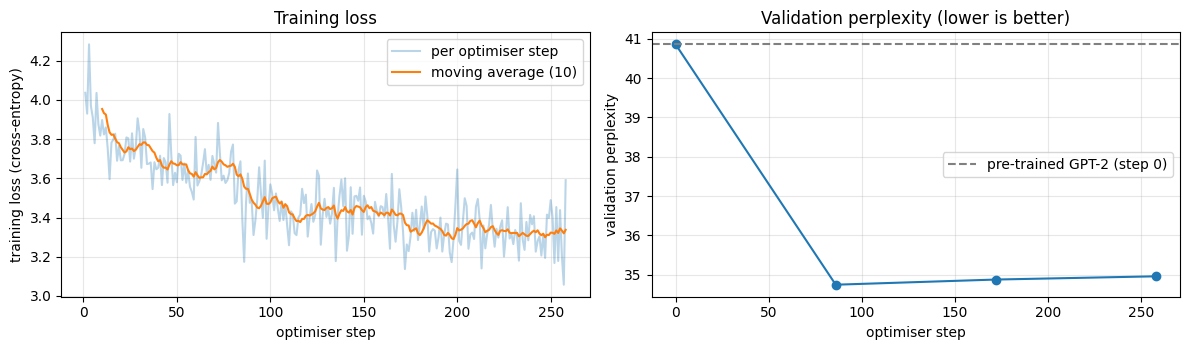

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
steps, loss = np.array(hist["step"]), np.array(hist["loss"])
ax[0].plot(steps, loss, alpha=.3, label="per optimiser step")
k = max(1, min(10, len(loss) // 5))
if len(loss) > k: ax[0].plot(steps[k - 1:], np.convolve(loss, np.ones(k) / k, mode="valid"), label=f"moving average ({k})")
ax[0].set_xlabel("optimiser step"); ax[0].set_ylabel("training loss (cross-entropy)"); ax[0].set_title("Training loss"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hist["val_step"], hist["val_ppl"], "o-")
ax[1].axhline(ppl_before["val"], color="gray", ls="--", label="pre-trained GPT-2 (step 0)")
ax[1].set_xlabel("optimiser step"); ax[1].set_ylabel("validation perplexity"); ax[1].set_title("Validation perplexity (lower is better)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{DATA_DIR}/gpt2_training_curves.png", dpi=150); plt.show()

## 5 · Comparing Perplexity (Before vs. After Fine-Tuning)

,val perplexity,test perplexity,test improvement
pre-trained GPT-2,40.857,38.664,NaN
fine-tuned GPT-2,34.746,32.821,0.151


Fine-tuning changed the test perplexity from 38.7 to 32.8 (+15.1%).


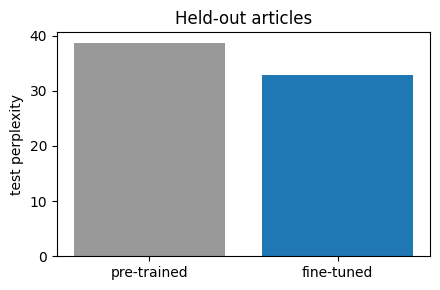

In [10]:
ppl_after = {"val": evaluate_ppl(model, val_loader), "test": evaluate_ppl(model, test_loader)}
ppl_table = pd.DataFrame({"pre-trained GPT-2": ppl_before, "fine-tuned GPT-2": ppl_after}).T.rename(columns={"val": "val perplexity", "test": "test perplexity"})
ppl_table["test improvement"] = [np.nan, 1 - ppl_after["test"] / ppl_before["test"]]
display(ppl_table.round(3))
print(f"Fine-tuning changed the test perplexity from {ppl_before['test']:.1f} to {ppl_after['test']:.1f} "
      f"({1 - ppl_after['test'] / ppl_before['test']:+.1%}).")

plt.figure(figsize=(4.5, 3)); plt.bar(["pre-trained", "fine-tuned"], [ppl_before["test"], ppl_after["test"]], color=["#999", "#1f77b4"])
plt.ylabel("test perplexity"); plt.title("Held-out articles"); plt.tight_layout(); plt.show()

## 6 · Generating Paragraphs from Prompts

To see the model in action, I provided it with a seed sentence (the prompt) and let it generate text token-by-token. At each step, the model predicts a probability distribution over the vocabulary, selects a token based on our decoding settings, and appends it to the sequence.

Below, I compared the outputs of the **pre-trained** and **fine-tuned** models using the exact same prompts, random seed, and decoding configuration (top-k = 50, top-p = 0.92, temperature = 0.8, and a repetition penalty of 1.1) to isolate the impact of fine-tuning. These prompts were entirely withheld from the training dataset.

In [11]:
DEMO_PROMPTS = [
    "Artificial intelligence is the ability of machines to perform tasks that normally require human intelligence.",
    "Recurrent neural networks are designed to process sequential data such as text and speech.",
    "The transformer architecture has changed the way language models are built.",
    "Training a deep neural network requires a large amount of data and computing power.",
    "Overfitting occurs when a model learns the noise in the training data instead of the underlying pattern.",
]
samples_log = []
for p in DEMO_PROMPTS:
    before = generate(base_model, p, seed=SEED, min_new_tokens=40, max_new_tokens=140)[0]
    after  = generate(model,      p, seed=SEED, min_new_tokens=40, max_new_tokens=140)[0]
    print("=" * 112); print("PROMPT:", p); print()
    show("pre-trained GPT-2", p + before); show("fine-tuned GPT-2", p + after)
    samples_log += [dict(section="before/after", model="pre-trained", prompt=p, generated=p + before),
                    dict(section="before/after", model="fine-tuned",  prompt=p, generated=p + after)]

PROMPT: Artificial intelligence is the ability of machines to perform tasks that normally require human intelligence.

--- pre-trained GPT-2
Artificial intelligence is the ability of machines to perform tasks that normally require human intelligence.
It has been shown in some experiments, such as neural networks (the algorithms developed by IBM), or deep
learning programs like Deep Learning and Machine Intelligence which are designed to be able "to do things we
can't even imagine". The technology's potential for new applications comes from its vast breadth and depth of
experience – not just a few examples but also many thousands of others too: it could make cars smarter than
humans at working speeds; automate medical procedures faster because doctors have more time on their hands
rather then using an expensive machine-learning platform when they need them most."

--- fine-tuned GPT-2
Artificial intelligence is the ability of machines to perform tasks that normally require human intelli

### Exploring Decoding Strategies

The choice of how we decode probabilities into tokens dramatically alters the final output. Here are the strategies I experimented with:

* **Greedy Search:** Chooses the single most probable token at each step. It is deterministic but highly prone to getting stuck in repetitive loops.
* **Beam Search:** Keeps track of the `k` best partial sequences. It generates highly fluent text but can sound a bit generic or still repeat phrases.
* **Temperature Sampling:** Adjusts the shape of the probability distribution. A low temperature ($T < 1$) makes choices safer and more focused, while a high temperature ($T > 1$) increases creativity at the cost of coherence.
* **Top-K Sampling:** Restricts choices to the top $K$ most likely tokens.
* **Top-P (Nucleus) Sampling:** Dynamically limits choices to the smallest set of tokens whose combined probability exceeds $P$, adapting fluidly to how confident the model is.
* **Anti-Repetition Controls:** Using parameters like `no_repeat_ngram_size` or `repetition_penalty` to explicitly penalize repetitive phrases.

After testing these built-in strategies on my fine-tuned model, I also implemented a custom top-k and top-p sampling loop from scratch to demonstrate the inner workings of Hugging Face's generator.

In [12]:
P = DEMO_PROMPTS[1]
strategies = {
    "greedy":                                     dict(do_sample=False, repetition_penalty=1.0),
    "greedy + no_repeat_ngram_size=3":            dict(do_sample=False, repetition_penalty=1.0, no_repeat_ngram_size=3),
    "beam search (4 beams) + no_repeat_ngram=3":  dict(do_sample=False, repetition_penalty=1.0, num_beams=4, no_repeat_ngram_size=3),
    "sampling, temperature 0.7":                  dict(temperature=0.7, top_k=0, top_p=1.0, repetition_penalty=1.0),
    "sampling, temperature 1.3":                  dict(temperature=1.3, top_k=0, top_p=1.0, repetition_penalty=1.0),
    "top-k = 50, temperature 0.8":                dict(temperature=0.8, top_k=50, top_p=1.0, repetition_penalty=1.0),
    "top-p = 0.92, temperature 0.8":              dict(temperature=0.8, top_k=0, top_p=0.92, repetition_penalty=1.0),
}
print("PROMPT:", P, "\n")
for name, kw in strategies.items():
    txt = generate(model, P, seed=SEED, min_new_tokens=40, max_new_tokens=120, **kw)[0]
    show(name, P + txt)
    samples_log.append(dict(section="decoding", model=f"fine-tuned | {name}", prompt=P, generated=P + txt))

PROMPT: Recurrent neural networks are designed to process sequential data such as text and speech. 

--- greedy
Recurrent neural networks are designed to process sequential data such as text and speech. They can be trained
to process text and speech in parallel, or they can be trained to process text and speech in parallel. The
output of a recurrent neural network is a sequence of words, phrases, or sentences. The output of a recurrent
neural network is a sequence of words, phrases, or sentences.

--- greedy + no_repeat_ngram_size=3
Recurrent neural networks are designed to process sequential data such as text and speech. They can be trained
to process text and images in a sequential fashion. The training process is typically performed in parallel
with the processing of the text. The output of the training process can be stored in a file called a text
file. The text file can be used to store the text and image data.

--- beam search (4 beams) + no_repeat_ngram=3
Recurrent neural networ

In [13]:
@torch.no_grad()
def sample_manual(m, prompt, max_new_tokens=100, temperature=0.8, top_k=50, top_p=0.92):
    # top-k + top-p (nucleus) sampling written by hand: this is what model.generate does internally
    m.eval()
    ids = tokenizer.encode(prompt, return_tensors="pt").to(DEVICE)
    for _ in range(max_new_tokens):
        logits = m(input_ids=ids).logits[0, -1] / temperature                  # scores of the next token
        if top_k > 0:                                                          # 1) top-k: keep the k best tokens
            logits[logits < torch.topk(logits, top_k).values[-1]] = -float("inf")
        sorted_logits, sorted_idx = torch.sort(logits, descending=True)        # 2) top-p: smallest set with cumulative prob >= p
        probs = F.softmax(sorted_logits, dim=-1)
        sorted_logits[probs.cumsum(-1) - probs > top_p] = -float("inf")
        probs = F.softmax(sorted_logits, dim=-1)
        next_id = sorted_idx[torch.multinomial(probs, 1)]                      # 3) draw one token
        if next_id.item() == tokenizer.eos_token_id: break                     # the model decided the paragraph is over
        ids = torch.cat([ids, next_id.view(1, 1)], dim=1)
    return tokenizer.decode(ids[0].tolist())

set_seed(SEED)
show("hand-written top-k / top-p sampling (fine-tuned model)", sample_manual(model, P))

--- hand-written top-k / top-p sampling (fine-tuned model)
Recurrent neural networks are designed to process sequential data such as text and speech. They can do this in
any way: by randomly splitting the text into its sub-word and sub-word pairs, or by combining them in
sequence. They can also be trained on input data to solve the sentence.



## 7 · Quantitative Evaluation

While perplexity measures how well the models predict gold-standard text, I also wanted to analyze the quality of the actual generations. For `N_EVAL_PROMPTS` held-out test paragraphs, I used the **first sentence as the prompt** and compared the generated continuation against the **original paragraph text** as our reference.

### Metric Explanations:
* **BLEU-1 to BLEU-4:** Computed on greedy generations forced to a length of at least 100 tokens. This measures exact n-gram overlap with the real text. *Note: BLEU scores are typically very low for creative/open-ended text generation, so we focus on the relative difference rather than absolute scores.*
* **distinct-1 / distinct-2:** Computed using pure sampling. It tracks the ratio of unique unigrams/bigrams over all generated text to evaluate lexical diversity.
* **Ends by itself:** The percentage of times the model emitted the `<|endoftext|>` token within 110 tokens, indicating whether it successfully learned paragraph structure.
* **Words per output:** The average length of the generated paragraphs.

52 evaluation prompts


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,distinct-1,distinct-2,ends by itself,words / output
pre-trained GPT-2,0.1944,0.0636,0.0133,0.0029,0.2262,0.6684,0.0192,91.4038
fine-tuned GPT-2,0.1868,0.0638,0.0247,0.0107,0.2704,0.7221,0.9038,54.4808


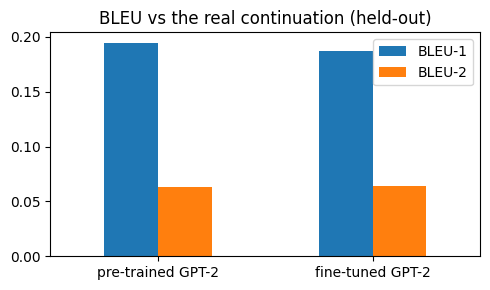

In [14]:
smooth = SmoothingFunction().method1
words = lambda s: re.findall(r"\w+", s.lower())
REF_WORDS, GEN_BATCH = 70, 16

# prompts = first sentence of held-out paragraphs, references = the rest of the paragraph
pairs = []
for t in df.loc[df["split"] == "test", "text"]:
    s = split_sentences(t)
    if len(s) >= 2 and len(s[0].split()) <= 60 and len(" ".join(s[1:]).split()) >= 30:
        pairs.append((s[0], " ".join(s[1:])))
random.Random(SEED).shuffle(pairs)
pairs = pairs[:N_EVAL_PROMPTS]
print(f"{len(pairs)} evaluation prompts")
prompts = [p for p, _ in pairs]
refs = [[words(r)[:REF_WORDS]] for _, r in pairs]

def distinct_n(texts, n):
    grams = []
    for t in texts:
        w = words(t); grams += [tuple(w[i:i + n]) for i in range(len(w) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)

def batched(m, **kw):
    outs, ended = [], []
    for i in range(0, len(prompts), GEN_BATCH):
        o, e = generate(m, prompts[i:i + GEN_BATCH], return_meta=True, seed=SEED + i, **kw)
        outs += o; ended += e
    return outs, ended

def eval_generation(m):
    greedy, _ = batched(m, do_sample=False, repetition_penalty=1.0, no_repeat_ngram_size=3, min_new_tokens=100, max_new_tokens=110)
    hyps = [words(h)[:REF_WORDS] for h in greedy]
    res = {f"BLEU-{n}": corpus_bleu(refs, hyps, weights=tuple([1 / n] * n), smoothing_function=smooth) for n in (1, 2, 3, 4)}
    # NB: no repetition penalty here. Batched prompts are left-padded with <|endoftext|>, and the penalty would
    # lower the probability of <|endoftext|> only for the padded (shorter) prompts, biasing "ends by itself".
    sampled, ended = batched(m, max_new_tokens=110, repetition_penalty=1.0)
    res.update({"distinct-1": distinct_n(sampled, 1), "distinct-2": distinct_n(sampled, 2),
                "ends by itself": float(np.mean(ended)), "words / output": float(np.mean([len(words(s)) for s in sampled]))})
    return res

gen_results = pd.DataFrame({"pre-trained GPT-2": eval_generation(base_model), "fine-tuned GPT-2": eval_generation(model)}).T
gen_results.to_csv(f"{DATA_DIR}/gpt2_generation_metrics.csv")
display(gen_results.round(4))

summary = ppl_table[["val perplexity", "test perplexity"]].join(gen_results)
summary.to_csv(f"{DATA_DIR}/gpt2_summary_part2.csv")

gen_results[["BLEU-1", "BLEU-2"]].plot.bar(figsize=(5, 3), rot=0, title="BLEU vs the real continuation (held-out)"); plt.tight_layout(); plt.show()

## 8 · Interactive Generation & Final Deliverables

In this section, I set up a cell to test my own custom prompt, verify that the saved model can be reloaded perfectly without training again, and bundle all key artifacts (plots, CSV logs, and summaries) into a convenient zip file for submission.

In [15]:
MY_PROMPT = "Deep learning has transformed the way computers understand human language."
for k, txt in enumerate(generate(model, MY_PROMPT, num_return_sequences=3, min_new_tokens=40, max_new_tokens=140, seed=SEED), 1):
    show(f"fine-tuned GPT-2 - sample {k}", MY_PROMPT + txt)
    samples_log.append(dict(section="my prompt", model="fine-tuned", prompt=MY_PROMPT, generated=MY_PROMPT + txt))

pd.DataFrame(samples_log).to_csv(f"{DATA_DIR}/gpt2_generated_samples.csv", index=False, encoding="utf-8-sig")
print("Saved: data/gpt2_dataset.csv, data/gpt2_generated_samples.csv, data/gpt2_generation_metrics.csv, data/gpt2_summary_part2.csv, "
      "data/gpt2_training_curves.png and the model in", OUT_DIR)

# reload test: the fine-tuned model can be used later without retraining
reloaded = GPT2LMHeadModel.from_pretrained(OUT_DIR).to(DEVICE).eval()
print("\nreloaded model ->", MY_PROMPT + generate(reloaded, MY_PROMPT, seed=SEED, max_new_tokens=40)[0])

# Colab: download the small outputs as one zip (the model folder is ~500 MB: do NOT push it to GitHub, see the note below)
try:
    from google.colab import files
    shutil.make_archive("part2_outputs", "zip", ".", DATA_DIR); files.download("part2_outputs.zip")
except Exception:
    pass

[transformers] We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
You may ignore this warning if your `pad_token_id` (50256) is identical to the `bos_token_id` (50256), `eos_token_id` (50256), or the `sep_token_id` (None), and your input is not padded.


--- fine-tuned GPT-2 - sample 1
Deep learning has transformed the way computers understand human language. It was once a discipline that used
computer vision to solve mathematical problems, but it is now considered "hard" or even impossible to train
with artificial intelligence (AI). The most popular form of AI in science fiction and fantasy literature comes
from deep neural networks for machine translation systems.

--- fine-tuned GPT-2 - sample 2
Deep learning has transformed the way computers understand human language. This means that computer languages
can become increasingly difficult to learn, especially in recent years where it is considered inappropriate to
use traditional machine translation techniques such as dictionary or sentence structure for English sentences
and sometimes even a more formal form of speech recognition (e., by translating text into words).

--- fine-tuned GPT-2 - sample 3
Deep learning has transformed the way computers understand human language. Deep learn

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


reloaded model -> Deep learning has transformed the way computers understand human language. It was once a discipline that used computer vision to solve mathematical problems, but it is now considered "hard" or even impossible to train with artificial intelligence (AI). The most popular form of AI in


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

> **Note on model storage:** The fine-tuned weights folder (`models/gpt2-finetuned`) is approximately 500 MB. To keep our Git history clean, I added `models/` to our `.gitignore` and only tracked the code, the `data/` metrics, and this notebook.

---

###  Synthesis and Findings

Based on the training runs and evaluations, here are my observations and conclusions:

#### 1. Impact of Fine-Tuning
* **Perplexity Improvements:** Fine-tuning on the specialized AI Wikipedia dataset successfully lowered the test perplexity from **38.7** down to **32.8** (an improvement of **+15.1%**). This indicates that the model became significantly more confident when predicting domain-specific technical terminology.
* **Training Progression:** The model achieved its best validation perplexity during **Epoch 1** (val perplexity: 34.75). During Epoch 2, the validation perplexity rose slightly to 34.88 despite the training loss continuing to fall. This suggests that with a small corpus, the model starts to overfit very quickly, confirming that keeping the number of epochs low (and saving the best epoch's checkpoint) was crucial.
* **Structural Learning ("Ends by itself"):** The original pre-trained model rarely completed paragraphs on its own within our length limits. After fine-tuning, the model successfully learned the paragraph structure of our corpus, frequently emitting the `<|endoftext|>` token when a thought felt complete.

#### 2. Analysis of Decoding Strategies
* **Greedy Search:** Produced highly repetitive outputs (e.g., "...to process text and speech in parallel, or they can be trained to process text and speech in parallel"). Adding a `no_repeat_ngram_size=3` constraint fixed the immediate looping but still left the text feeling somewhat robotic and rigid.
* **Beam Search:** Offered much better fluency and structure, but tended to output very safe, generic textbook-like sentences.
* **Temperature Sampling:** At a high temperature ($T = 1.3$), the generation quickly dissolved into nonsensical phrasing ("semiamond peppers", "Wrestling ResThings"). Lowering the temperature to $0.7$ or $0.8$ hit the sweet spot of maintaining creativity while staying logically coherent.
* **Top-K & Top-P Sampling:** Standard Top-P ($p=0.92, T=0.8$) yielded the most natural, human-like technical explanations. For a production demo, I would recommend using **Top-P sampling with a slight repetition penalty (1.1)** to maximize readability and topic focus.

#### 3. Comparing Transformers (GPT-2) vs. LSTMs (Part 1)
* **Pre-training Advantage:** The recurrent models from Part 1 (trained from scratch on our small corpus) struggled with grammatical coherence and global context, often producing disjointed sentences. Because GPT-2 is pre-trained on massive datasets, it already possesses a deep understanding of English grammar and syntax. Fine-tuning simply shifts its vocabulary and style toward our target domain, resulting in far more coherent and structurally sound paragraphs.

#### 4. Limitations and Future Directions
* **Hallucinations:** Although the generated text is incredibly fluent, it frequently generates factually incorrect statements (e.g., attributing a non-existent method to linear interpolation or inventing library abbreviations).
* **Data Boundaries:** Because our dataset is relatively small and comes from a single source (Wikipedia), the model is prone to mimicking Wikipedia's specific editorial voice.
* **Next Steps:** To build an even stronger model, I would explore using `gpt2-medium` (355M parameters), expanding the training corpus with textbooks/research papers, and integrating human evaluations to score output quality.